# SMS kampaniyası kimə göndərilməlidir? Uplift modeli

Bu notebook layihəni addım-addım göstərir və **Google Colab-da tam işləyir**: data internetdən endirilir,
feature-lər qurulur, model öyrədilir, sonda yeni müştərilər üçün proqnoz verilir.

**İşə salmaq:** menyudan `Runtime → Run all`. Bütün notebook təxminən 3–5 dəqiqəyə işləyir
(ən uzun hissə 600 MB-lıq alış faylının endirilməsidir).

| № | Bölmə |
|---|---|
| 1 | Data haradandır? |
| 2 | Datanı təmizləmə və harada istifadə etdim |
| 3 | Feature-ləri necə düzəltdim |
| 4 | Train / validation / test bölgüsü |
| 5 | Dummy model nə göstərdi |
| 6 | Model necə train olundu (T-learner) |
| 7 | Model necə qiymətləndirildi |
| 8 | Threshold: kimə göndərək? |
| 9 | Yekun test nəticəsi |
| 10 | **Yeni müştərilər üçün proqnoz** |

## 0. Hazırlıq: kitabxanalar və data

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("duckdb") is None:          # Colab-da yoxdursa quraşdırılır
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "duckdb"])

import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
print("Kitabxanalar hazırdır")

Kitabxanalar hazırdır


In [2]:
DATA = Path("data")
DATA.mkdir(exist_ok=True)
BASE = "https://huggingface.co/datasets/pytorch-lifestream/retailhero-uplift/resolve/main/data/"
for name in ["clients.csv.gz", "uplift_train.csv.gz", "products.csv.gz", "purchases.csv.gz"]:
    target = DATA / name
    if not target.exists():
        print(f"endirilir: {name} ...", flush=True)
        urllib.request.urlretrieve(BASE + name, target)
    print(f"hazırdır: {name}  ({target.stat().st_size / 1e6:.0f} MB)")

con = duckdb.connect()
PURCHASES = (DATA / "purchases.parquet").as_posix()
if not Path(PURCHASES).exists():                      # 45.8 mln sətir: bir dəfə parquet-ə çevrilir
    con.execute(f"COPY (SELECT * FROM read_csv_auto('{(DATA / 'purchases.csv.gz').as_posix()}')) TO '{PURCHASES}' (FORMAT parquet)")
print("alış faylı hazırdır")

hazırdır: clients.csv.gz  (8 MB)
hazırdır: uplift_train.csv.gz  (1 MB)
hazırdır: products.csv.gz  (1 MB)
hazırdır: purchases.csv.gz  (609 MB)
alış faylı hazırdır


## 1. Data haradandır?

**X5 RetailHero**: Rusiyanın ən böyük ərzaq şəbəkələrindən biri olan X5 Retail Group-un açıq yarışma datası
([ods.ai/competitions/x5-retailhero-uplift-modeling](https://ods.ai/competitions/x5-retailhero-uplift-modeling)).

Şirkət real SMS kampaniyası keçirib və müştəriləri **təsadüfi iki qrupa** bölüb:
- **treatment** (`treatment_flg = 1`): SMS göndərilib
- **control** (`treatment_flg = 0`): SMS göndərilməyib

Sonra hər müştərinin alış edib-etmədiyi qeyd olunub (`target = 1` alıb, `0` almayıb).

Data 4 fayldan ibarətdir:

In [3]:
CAMPAIGN_START = pd.Timestamp("2019-03-19")
clients = pd.read_csv(DATA / "clients.csv.gz", parse_dates=["first_issue_date", "first_redeem_date"])
campaign = pd.read_csv(DATA / "uplift_train.csv.gz")
products = pd.read_csv(DATA / "products.csv.gz")
n_lines, n_receipts, first_day, last_day = con.execute(
    f"SELECT count(*), count(DISTINCT transaction_id), min(transaction_datetime), max(transaction_datetime) FROM '{PURCHASES}'").fetchone()

pd.DataFrame({
    "nə var": ["müştəri: yaş, cins, kartın verilmə tarixi, ilk bonus istifadəsi",
               f"hər alınan məhsul: tarix, məbləğ, mağaza, bonus ({first_day:%Y-%m-%d} – {last_day:%Y-%m-%d})",
               "məhsul kataloqu: kateqoriya, öz brendi, alkoqol",
               "kampaniya: SMS alıb-almadığı və sonra alış edib-etmədiyi"],
    "sətir sayı": [f"{len(clients):,}", f"{n_lines:,} ({n_receipts:,} qəbz)", f"{len(products):,}", f"{len(campaign):,}"],
}, index=["clients.csv", "purchases.csv", "products.csv", "uplift_train.csv"])

,nə var,sətir sayı
clients.csv,"müştəri: yaş, cins, kartın verilmə tarixi, ilk...","400,162"
purchases.csv,"hər alınan məhsul: tarix, məbləğ, mağaza, bonu...","45,786,568 (8,045,201 qəbz)"
products.csv,"məhsul kataloqu: kateqoriya, öz brendi, alkoqol","43,038"
uplift_train.csv,kampaniya: SMS alıb-almadığı və sonra alış edi...,"200,039"


Kampaniya faylı: hər müştəri üçün **SMS aldımı** və **alış etdimi**.

In [4]:
campaign.head()

,client_id,treatment_flg,target
0,000012768d,0,1
1,000036f903,1,1
2,00010925a5,1,1
3,0001f552b0,1,1
4,00020e7b18,1,1


In [5]:
s = campaign.groupby("treatment_flg").target.agg(["size", "mean"])
s.index = ["SMS almayan (control)", "SMS alan (treatment)"]
s.columns = ["müştəri", "alış payı %"]
s["alış payı %"] = (s["alış payı %"] * 100).round(2)
print(f"Kampaniyanın orta effekti: +{s['alış payı %'].iloc[1] - s['alış payı %'].iloc[0]:.2f} faiz bəndi")
s

Kampaniyanın orta effekti: +3.32 faiz bəndi


,müştəri,alış payı %
SMS almayan (control),100058,60.33
SMS alan (treatment),99981,63.65


SMS alanların 63.7%-i, almayanların 60.3%-i alış edib. Yəni SMS orta hesabla alış payını **+3.3 bənd** artırır:
hər 100 SMS təxminən 3 əlavə alıcı gətirir. Amma bu, **orta** göstəricidir. Bəzi müştərilərdə effekt böyük, bəzilərində
sıfırdır. Bizim məqsədimiz effekti böyük olanları tapmaqdır.

## 2. Datanı təmizləmə və harada istifadə etdim

| Fayl | Harada istifadə olundu |
|---|---|
| `uplift_train.csv` | **hədəf** (alış etdimi) və **qrup** (SMS aldımı): modelin öyrəndiyi cavablar |
| `clients.csv` | yaş, cins, kartın yaşı, bonus istifadəsi |
| `purchases.csv` | 45.8 mln sətirdən hər müştəri üçün **xülasə**: neçə dəfə alıb, nə qədər xərcləyib, son alış nə vaxt olub |
| `products.csv` | layihədə əlavə təcrübə üçün (bu notebook-da lazım deyil) |

**Əsas qayda:** yalnız kampaniyadan **əvvəlki** məlumat istifadə olunur. Əks halda model "gələcəyi görər"
(**data leakage**). Təmizləmə zamanı tapılan problemlər:

In [6]:
bad_age = ~clients.age.between(14, 100)
leak = clients.first_redeem_date >= CAMPAIGN_START
print(f"Mümkünsüz yaş (məs. {clients.age.min():.0f}, {clients.age.max():.0f}): {bad_age.sum():,} müştəri → 'naməlum' sayıldı")
print(f"İlk bonus tarixi kampaniyadan SONRA ({clients.first_redeem_date.max():%Y-%m-%d}-ə qədər): {leak.sum():,} müştəri → leakage, tarix silindi")

clients["age_invalid"] = bad_age
clients.loc[bad_age, "age"] = np.nan
clients.loc[leak, "first_redeem_date"] = pd.NaT                 # leakage düzəlişi
clients["redeemed_before_campaign"] = clients.first_redeem_date.notna()

Mümkünsüz yaş (məs. -7491, 1901): 1,779 müştəri → 'naməlum' sayıldı
İlk bonus tarixi kampaniyadan SONRA (2019-11-20-ə qədər): 44,953 müştəri → leakage, tarix silindi


## 3. Feature-ləri necə düzəltdim

Model bir müştəri üçün **bir sətir** görməlidir, alış faylında isə bir müştərinin onlarla sətri var.
Ona görə alışlar müştəri səviyyəsində **xülasə edilir (aggregation)**. Əvvəlcə bir müştərinin xam alışlarına baxaq:

In [7]:
example_id = campaign.client_id.iloc[7]
raw = con.execute(f'''
    SELECT transaction_id, transaction_datetime, purchase_sum, store_id, product_id, product_quantity
    FROM '{PURCHASES}' WHERE client_id = '{example_id}' ORDER BY transaction_datetime''').df()
print(f"Müştəri {example_id}: {len(raw)} məhsul sətri, {raw.transaction_id.nunique()} qəbz")
raw.head(8)

Müştəri 0002ce2217: 72 məhsul sətri, 13 qəbz


,transaction_id,transaction_datetime,purchase_sum,store_id,product_id,product_quantity
0,7a54584286,2018-12-09 13:09:48,128.52,5910928e8d,53fc95e177,1.0
1,7a54584286,2018-12-09 13:09:48,128.52,5910928e8d,4055b15e4a,1.0
2,7a54584286,2018-12-09 13:09:48,128.52,5910928e8d,a1589a8d81,1.0
3,7a54584286,2018-12-09 13:09:48,128.52,5910928e8d,6d237b22d5,2.0
4,7a54584286,2018-12-09 13:09:48,128.52,5910928e8d,9c0db0fdb3,1.0
5,4fcc20fcf4,2018-12-21 13:25:22,62.00,5910928e8d,a102a77114,1.0
6,4fcc20fcf4,2018-12-21 13:25:22,62.00,5910928e8d,6d237b22d5,3.0
7,3681906a6f,2018-12-25 13:25:42,161.32,5910928e8d,7036db4854,1.0


**Diqqət:** `purchase_sum` qəbzin **ümumi** məbləğidir və qəbzdəki hər məhsul sətrində təkrarlanır.
Sadəcə toplasaq, xərc təxminən 10 dəfə şişər. Ona görə əvvəlcə hər qəbz bir dəfə götürülür, sonra müştəri üzrə toplanır.
Bunu bütün 400 min müştəri üçün DuckDB ilə edirik:

In [8]:
agg = con.execute(f'''
    WITH receipts AS (                                -- 1) hər qəbz bir sətir
        SELECT client_id, transaction_id,
               any_value(transaction_datetime)    AS ts,
               any_value(purchase_sum)            AS receipt_sum,
               any_value(store_id)                AS store_id,
               any_value(regular_points_received) AS pts_received,
               any_value(regular_points_spent)    AS pts_spent,
               sum(product_quantity)              AS items
        FROM '{PURCHASES}'
        WHERE transaction_datetime < TIMESTAMP '{CAMPAIGN_START}'
        GROUP BY client_id, transaction_id)
    SELECT client_id,                                 -- 2) hər müştəri bir sətir
           count(*)                     AS n_transactions,
           sum(receipt_sum)             AS total_spend,
           avg(receipt_sum)             AS avg_basket,
           avg(items)                   AS avg_items,
           count(DISTINCT store_id)     AS n_stores,
           sum(pts_received)            AS points_received,
           abs(sum(pts_spent))          AS points_spent,
           date_diff('day', max(ts), TIMESTAMP '{CAMPAIGN_START}') AS days_since_last_purchase,
           date_diff('day', min(ts), TIMESTAMP '{CAMPAIGN_START}') AS days_since_first_purchase
    FROM receipts GROUP BY client_id''').df()

df = (campaign.merge(clients, on="client_id", how="left").merge(agg, on="client_id", how="left"))
df["card_age_days"] = (CAMPAIGN_START - df.first_issue_date).dt.days
df["days_since_first_redeem"] = (CAMPAIGN_START - df.first_redeem_date).dt.days
df["redeem_before_issue"] = df.days_since_first_redeem > df.card_age_days       # data səhvi bayrağı
print(f"Hazır cədvəl: {len(df):,} müştəri x {df.shape[1]} sütun")

Hazır cədvəl: 200,039 müştəri x 21 sütun


Yoxlama: həmin müştəri üçün əl ilə hesablanan və pipeline-ın hesabladığı rəqəmlər eyni olmalıdır:

In [9]:
receipts = raw.groupby("transaction_id").agg(ts=("transaction_datetime", "first"), s=("purchase_sum", "first"), store=("store_id", "first"))
row = df.set_index("client_id").loc[example_id]
pd.DataFrame({
    "əl ilə": [len(receipts), round(receipts.s.sum(), 2), round(receipts.s.mean(), 2), receipts.store.nunique(),
               (CAMPAIGN_START - receipts.ts.max().normalize()).days],
    "pipeline": [row.n_transactions, round(row.total_spend, 2), round(row.avg_basket, 2), row.n_stores, row.days_since_last_purchase],
}, index=["qəbz sayı", "ümumi xərc", "orta səbət", "mağaza sayı", "son alışdan keçən gün"]).assign(
    **{"YANLIŞ toplama (təkrarla)": ["", round(raw.purchase_sum.sum(), 2), "", "", ""]})

,əl ilə,pipeline,YANLIŞ toplama (təkrarla)
qəbz sayı,13.00,13.00,
ümumi xərc,3305.03,3305.03,28963.21
orta səbət,254.23,254.23,
mağaza sayı,5.00,5.00,
son alışdan keçən gün,2.00,2.00,


Modelə daxil olan **16 feature**:

| Feature | Mənası |
|---|---|
| `age`, `gender`, `age_invalid` | yaş, cins, yaş səhv idimi |
| `card_age_days` | loyallıq kartı neçə gündür var |
| `redeemed_before_campaign`, `days_since_first_redeem`, `redeem_before_issue` | bonus istifadə edibmi, nə vaxtdan |
| `n_transactions` | 4 ayda qəbz sayı |
| `total_spend`, `avg_basket`, `avg_items` | ümumi xərc, orta səbət, səbətdə məhsul sayı |
| `n_stores` | neçə fərqli mağazadan alıb |
| `points_received`, `points_spent` | qazandığı və xərclədiyi bonus |
| `days_since_last_purchase`, `days_since_first_purchase` | son və ilk alışdan keçən gün |

Modeldən əvvəl **Pipeline** daxilində: boş dəyərlər median ilə doldurulur, pul və say göstəriciləri `log` ilə sıxılır,
hamısı standartlaşdırılır, cins one-hot ilə kodlanır. Pipeline eyni hazırlığın həm təlimdə, həm də proqnozda
tətbiq olunmasını təmin edir.

In [10]:
LOG = ["n_transactions", "total_spend", "avg_basket", "avg_items", "n_stores", "points_received", "points_spent"]
NUM = ["age", "card_age_days", "days_since_first_redeem", "days_since_last_purchase", "days_since_first_purchase"]
BOOL = ["age_invalid", "redeemed_before_campaign", "redeem_before_issue"]
CAT = ["gender"]
FEATURES = LOG + NUM + BOOL + CAT

def log1p_clip(a):
    return np.log1p(np.clip(a, 0, None))

def make_pipeline_model():
    prep = ColumnTransformer([
        ("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(log1p_clip, feature_names_out="one-to-one"), StandardScaler()), LOG),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM),
        ("missing", MissingIndicator(features="missing-only", error_on_new=False), LOG + NUM),
        ("bool", "passthrough", BOOL),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=3000))])

def X_of(d):
    X = d[FEATURES].copy()
    X[BOOL] = X[BOOL].astype(float)
    X["gender"] = X["gender"].astype(str)
    return X

df.loc[df.client_id == example_id, FEATURES].T.rename(columns=lambda c: "nümunə müştərinin feature-ləri")

,nümunə müştərinin feature-ləri
n_transactions,13
total_spend,3305.03
avg_basket,254.233077
avg_items,6.923077
n_stores,5
points_received,22.5
points_spent,0.0
age,38.0
card_age_days,600
days_since_first_redeem,555.0


## 4. Train / validation / test bölgüsü

| Hissə | Pay | Nə üçün |
|---|---|---|
| **train** | 60% | model buradan öyrənir |
| **validation** | 20% | modelləri müqayisə edib ən yaxşısını seçmək üçün |
| **test** | 20% | **yalnız sonda, bir dəfə**: yekun dürüst nəticə |

Bölgü **stratified** aparılıb: hər hissədə SMS alanların payı və alış payı eynidir.

In [11]:
strata = df.treatment_flg.astype(str) + "_" + df.target.astype(str)
train_idx, rest_idx = train_test_split(df.index, train_size=0.6, stratify=strata, random_state=42)
valid_idx, test_idx = train_test_split(rest_idx, train_size=0.5, stratify=strata.loc[rest_idx], random_state=42)
df["split"] = "train"
df.loc[valid_idx, "split"] = "valid"
df.loc[test_idx, "split"] = "test"
train, valid, test = df[df.split == "train"], df[df.split == "valid"], df[df.split == "test"]

def part(g):
    t, y = g.treatment_flg, g.target
    return pd.Series({"müştəri": len(g), "SMS alanlar %": t.mean() * 100, "alış % (SMS-siz)": y[t == 0].mean() * 100,
                      "alış % (SMS-li)": y[t == 1].mean() * 100, "effekt (bənd)": (y[t == 1].mean() - y[t == 0].mean()) * 100})
pd.DataFrame({name: part(g) for name, g in [("train", train), ("valid", valid), ("test", test)]}).T.round(2)

,müştəri,SMS alanlar %,alış % (SMS-siz),alış % (SMS-li),effekt (bənd)
train,120023.0,49.98,60.33,63.65,3.32
valid,40008.0,49.98,60.33,63.65,3.32
test,40008.0,49.98,60.33,63.65,3.32


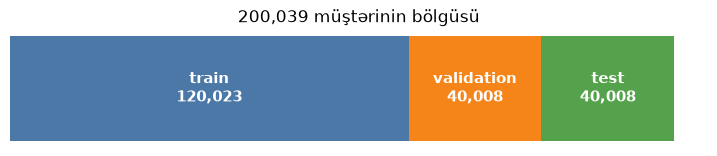

In [12]:
fig, ax = plt.subplots(figsize=(9, 1.5))
left = 0
for name, g, color in [("train", train, "#4C78A8"), ("validation", valid, "#F58518"), ("test", test, "#54A24B")]:
    ax.barh(0, len(g), left=left, color=color)
    ax.text(left + len(g) / 2, 0, f"{name}\n{len(g):,}", ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left += len(g)
ax.axis("off"); ax.set_title(f"{len(df):,} müştərinin bölgüsü"); plt.show()

## 5. Dummy model nə göstərdi?

Hər ML layihəsində əvvəlcə **ən sadə müqayisə nöqtəsi** qurulur.

**a) `DummyClassifier`: hamıya "alacaq" deyir.** Accuracy yüksək görünür, çünki müştərilərin təxminən 62%-i alış edir.
Bu, accuracy-nin burada niyə **aldadıcı** olduğunu göstərir.

In [13]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_of(train), train.target)
acc = (dummy.predict(X_of(valid)) == valid.target).mean()
print(f"DummyClassifier hamıya 'alacaq' deyir → accuracy = {acc:.1%}")
print("Amma heç bir müştərini digərindən ayırmır: kimə SMS göndərmək lazım olduğu barədə heç nə demir.")

DummyClassifier hamıya 'alacaq' deyir → accuracy = 62.0%
Amma heç bir müştərini digərindən ayırmır: kimə SMS göndərmək lazım olduğu barədə heç nə demir.


**b) Uplift üçün dummy: "SMS hamıya eyni təsir edir".** Müştəriləri sıralaya bilmir, yəni seçimi təsadüfidir.

Bunu iki modellə müqayisə edəcəyik:
- **Klassik "kim alacaq" modeli:** şirkətlərin çoxu belə edir. Yalnız SMS alanlardan öyrənir və alış ehtimalı ən yüksək olanları seçir.
- **Uplift modeli:** SMS-in **effekti** ən böyük olanları seçir (növbəti bölmə).

Müqayisə metrikası **uplift@10%**: modelin ən yuxarıda sıraladığı 10% müştəridə SMS alanların və almayanların alış payı fərqi.

In [14]:
def uplift_at_k(score, t, y, k):
    top = np.argsort(-np.asarray(score), kind="stable")[: int(len(score) * k)]
    t, y = np.asarray(t)[top], np.asarray(y)[top]
    return y[t == 1].mean() - y[t == 0].mean()

def qini_curve(score, t, y):
    o = np.argsort(-np.asarray(score), kind="stable")
    t, y = np.asarray(t)[o], np.asarray(y)[o]
    ct, cc = np.cumsum(t), np.cumsum(1 - t)
    q = np.cumsum(y * t) - np.cumsum(y * (1 - t)) * ct / np.maximum(cc, 1)
    x = np.arange(1, len(t) + 1) / len(t)
    return np.r_[0, x], np.r_[0, q / len(t)]

def qini_coefficient(score, t, y):
    x, q = qini_curve(score, t, y)
    diff = q - x * q[-1]
    return float(np.sum((diff[1:] + diff[:-1]) / 2 * np.diff(x)))

class TLearner:
    """İki model: biri SMS alanlardan, biri almayanlardan öyrənir. Uplift = fərq."""
    def fit(self, d):
        t = d.treatment_flg == 1
        self.m1 = make_pipeline_model().fit(X_of(d[t]), d.target[t])
        self.m0 = make_pipeline_model().fit(X_of(d[~t]), d.target[~t])
        return self
    def predict_arms(self, d):
        X = X_of(d)
        return self.m1.predict_proba(X)[:, 1], self.m0.predict_proba(X)[:, 1]
    def predict_uplift(self, d):
        p1, p0 = self.predict_arms(d)
        return p1 - p0

t_tr = train.treatment_flg == 1
response = make_pipeline_model().fit(X_of(train[t_tr]), train.target[t_tr])     # klassik model
tlearner = TLearner().fit(train)

t_va, y_va = valid.treatment_flg.to_numpy(), valid.target.to_numpy()
scores = {
    "Dummy (hamıya eyni)": np.random.default_rng(0).random(len(valid)),
    "Klassik 'kim alacaq' modeli": response.predict_proba(X_of(valid))[:, 1],
    "Uplift modeli (T-learner)": tlearner.predict_uplift(valid),
}
pd.DataFrame({name: {"ən yaxşı 10%-də effekt (bənd)": uplift_at_k(s, t_va, y_va, 0.1) * 100,
                     "ən yaxşı 30%-də effekt (bənd)": uplift_at_k(s, t_va, y_va, 0.3) * 100,
                     "Qini ×1000": qini_coefficient(s, t_va, y_va) * 1000} for name, s in scores.items()}).T.round(2)

,ən yaxşı 10%-də effekt (bənd),ən yaxşı 30%-də effekt (bənd),Qini ×1000
Dummy (hamıya eyni),0.74,3.26,-0.50
Klassik 'kim alacaq' modeli,0.39,1.42,-2.18
Uplift modeli (T-learner),10.26,6.46,3.02


**Nəticə (validation):**
- **Dummy** seçim etmir: 30%-də nəticəsi orta effektə (+3.3) bərabərdir, 10%-də isə kiçik qrupun səs-küyü səbəbindən təsadüfən aşağı çıxıb.
- **Klassik model dummy-dən də pisdir.** Ən çox alacaq adamları seçir, onlar isə SMS olmadan da alır.
- **Uplift modeli** seçdiyi 10%-də effekti təxminən **3 dəfə** artırır.

Klassik modelin seçdiklərinin SMS-siz alış payı:

In [15]:
top_resp = np.argsort(-scores["Klassik 'kim alacaq' modeli"])[: len(valid) // 10]
print(f"Klassik modelin ən yaxşı 10%-i SMS OLMADAN {y_va[top_resp][t_va[top_resp] == 0].mean():.0%} alış edir → SMS heç nə dəyişmir")

Klassik modelin ən yaxşı 10%-i SMS OLMADAN 95% alış edir → SMS heç nə dəyişmir


## 6. Model necə train olundu (T-learner)

Bir müştərini eyni anda həm SMS-li, həm SMS-siz görə bilmirik. Ona görə **iki model** qurulur:

1. **Model 1**: yalnız SMS **alan** müştərilərdən öyrənir → "SMS olsa, bu adam alarmı?"
2. **Model 0**: yalnız SMS **almayan** müştərilərdən öyrənir → "SMS olmasa, bu adam alarmı?"

**Uplift = Model 1-in ehtimalı − Model 0-ın ehtimalı**. Hər iki model eyni Pipeline-dır: hazırlıq + `LogisticRegression`.

Layihədə 17 fərqli modeli müqayisə etdim (gradient boosting, causal forest və s.). Effekt kiçik olduğu üçün
mürəkkəb modellər səs-küyü öyrəndi və daha pis çıxdı, ən sadə model qalib gəldi.

In [16]:
print(f"Model 1 (SMS alanlar) train ölçüsü:    {t_tr.sum():,}")
print(f"Model 0 (SMS almayanlar) train ölçüsü: {(~t_tr).sum():,}")
tlearner.m1

Model 1 (SMS alanlar) train ölçüsü:    59,988
Model 0 (SMS almayanlar) train ölçüsü: 60,035


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['n_transactions','total_spend','avg_basket',..., 'redeemed_before_campaign','redeem_before_issue','gender']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

Validation-dan 5 müştəri: iki modelin ehtimalları və aralarındakı fərq:

In [17]:
sample = valid.sample(5, random_state=3)
p1, p0 = tlearner.predict_arms(sample)
pd.DataFrame({"yaş": sample.age.values, "qəbz sayı": sample.n_transactions.values, "orta səbət": sample.avg_basket.round(0).values,
              "P(alış | SMS)": p1.round(3), "P(alış | SMS yox)": p0.round(3), "uplift (bənd)": ((p1 - p0) * 100).round(2)},
             index=sample.client_id.values)

,yaş,qəbz sayı,orta səbət,P(alış | SMS),P(alış | SMS yox),uplift (bənd)
a834a388e3,31.0,22,792.0,0.784,0.754,2.94
a557305a9a,23.0,9,390.0,0.472,0.417,5.54
328f14d21f,66.0,9,660.0,0.469,0.398,7.13
d1300b2828,27.0,9,324.0,0.474,0.463,1.15
7cc1baa037,16.0,22,354.0,0.707,0.711,-0.41


Model nəyi öyrənib: hər feature SMS-in effektini hansı istiqamətdə dəyişir (Model 1 əmsalı − Model 0 əmsalı):

In [18]:
names = [n.split("__", 1)[1] for n in tlearner.m1.named_steps["prep"].get_feature_names_out()]
w = pd.Series(tlearner.m1.named_steps["clf"].coef_[0] - tlearner.m0.named_steps["clf"].coef_[0], index=names)
w.reindex(w.abs().sort_values(ascending=False).index).head(8).round(3).to_frame("effektə təsiri (+ artırır, − azaldır)")

,"effektə təsiri (+ artırır, − azaldır)"
total_spend,-0.419
n_transactions,0.239
avg_basket,0.133
card_age_days,-0.098
age,0.075
redeemed_before_campaign,0.073
gender_F,0.063
points_received,0.054


## 7. Model necə qiymətləndirildi

Accuracy burada işləmir, çünki heç bir müştəri üçün "SMS-in faktiki effektini" bilmirik.
**Qini əyrisi** göstərir: müştərilərin neçə faizinə göndərsək, neçə əlavə alış qazanırıq. Əyri nə qədər yuxarıdadırsa,
model o qədər yaxşıdır. Düz xətt təsadüfi seçimdir.

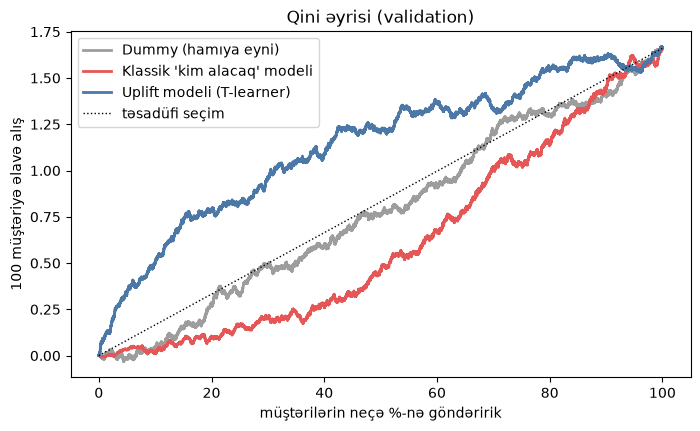

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, s), color in zip(scores.items(), ["#9D9D9D", "#E45756", "#4C78A8"]):
    x, q = qini_curve(s, t_va, y_va)
    ax.plot(x * 100, q * 100, label=name, color=color, lw=2)
ax.plot([0, 100], [0, q[-1] * 100], ls=":", color="black", lw=1, label="təsadüfi seçim")
ax.set_xlabel("müştərilərin neçə %-nə göndəririk"); ax.set_ylabel("100 müştəriyə əlavə alış")
ax.set_title("Qini əyrisi (validation)"); ax.legend(); plt.show()

Müştərilər modelin balına görə 10 qrupa (decil) bölünüb, 1 = ən böyük proqnoz effekt:

In [20]:
u_va = scores["Uplift modeli (T-learner)"]
dec = pd.qcut(pd.Series(-u_va).rank(method="first"), 10, labels=range(1, 11)).to_numpy()
rows = []
for d in range(1, 11):
    m = dec == d
    tt, yy = t_va[m], y_va[m]
    rows.append({"decil": d, "alış % (SMS-siz)": yy[tt == 0].mean() * 100, "alış % (SMS-li)": yy[tt == 1].mean() * 100,
                 "faktiki effekt": (yy[tt == 1].mean() - yy[tt == 0].mean()) * 100, "proqnoz effekt": u_va[m].mean() * 100})
pd.DataFrame(rows).set_index("decil").round(1)

,alış % (SMS-siz),alış % (SMS-li),faktiki effekt,proqnoz effekt
decil,,,,
1,42.1,52.4,10.2,9.1
2,48.2,53.8,5.6,6.2
3,53.5,56.8,3.3,4.9
4,56.4,59.1,2.7,4.0
5,61.1,63.0,1.9,3.2
6,64.4,67.0,2.5,2.5
7,70.9,70.2,-0.6,1.8
8,71.7,75.6,3.9,1.1
9,73.2,74.6,1.3,0.4


## 8. Threshold: kimə göndərək?

Adi klassifikasiyada threshold çox vaxt 0.5 olur: "ehtimal > 0.5 → alacaq". Bizdə threshold **puldan** gəlir.
Bir müştəriyə göndərmək o zaman sərfəlidir ki:

**effekt × alışın dəyəri > SMS qiyməti + P(alış | SMS) × kupon**

*Misal:* alışın dəyəri 100, SMS 2, kupon yoxdur → **threshold = 2 / 100 = 2 bənd**.

Müxtəlif threshold-larda validation hissəsində faktiki nəticə (qiymətlər ssenaridir, datada qiymət yoxdur):

In [21]:
def threshold_table(u, t, y, value, sms, coupon):
    rows = []
    for th in [-1, 0, 1, 2, 3, 4, 5, 6, 8]:
        sel = u * 100 >= th
        if sel.sum() < 300:
            continue
        rt, rc = y[sel & (t == 1)].mean(), y[sel & (t == 0)].mean()
        profit_per_client = (rt - rc) * value - sms - rt * coupon
        rows.append({"threshold (bənd)": th, "seçilən müştəri %": sel.mean() * 100,
                     "seçilənlərdə faktiki effekt": (rt - rc) * 100, "1000 müştəriyə mənfəət": 1000 * sel.mean() * profit_per_client})
    return pd.DataFrame(rows).set_index("threshold (bənd)").round(1)

print("Ssenari A: alışın dəyəri 100, SMS 2, kupon yoxdur")
display(threshold_table(u_va, t_va, y_va, 100, 2, 0))
print("Ssenari B: alışın dəyəri 100, SMS 2, kupon 10")
display(threshold_table(u_va, t_va, y_va, 100, 2, 10))

Ssenari A: alışın dəyəri 100, SMS 2, kupon yoxdur


,seçilən müştəri %,seçilənlərdə faktiki effekt,1000 müştəriyə mənfəət
threshold (bənd),,,
-1,95.1,3.3,1195.3
0,89.5,3.6,1416.0
1,77.2,3.9,1432.1
2,61.8,4.3,1435.4
3,47.3,5.2,1514.4
4,34.5,6.0,1395.3
5,24.1,6.9,1190.2
6,16.3,9.1,1151.7
8,6.7,11.7,649.9


Ssenari B: alışın dəyəri 100, SMS 2, kupon 10


,seçilən müştəri %,seçilənlərdə faktiki effekt,1000 müştəriyə mənfəət
threshold (bənd),,,
-1,95.1,3.3,-4865.5
0,89.5,3.6,-4276.9
1,77.2,3.9,-3338.8
2,61.8,4.3,-2208.9
3,47.3,5.2,-1167.7
4,34.5,6.0,-497.4
5,24.1,6.9,-106.4
6,16.3,9.1,295.7
8,6.7,11.7,301.7


- **Kupon yoxdursa**, orta effekt (3.3 bənd × 100 = 3.3) SMS qiymətindən (2) çoxdur, ona görə geniş seçim də qazanc gətirir.
  Ən yaxşı nəticə təxminən 3 bənd threshold-dadır: müştərilərin yarısına göndərmək hamıya göndərməkdən çox qazandırır.
- **Kupon 10 olanda** aşağı threshold **zərər** verir: SMS alıb onsuz da alış edən 60% müştəri kuponu boşuna istifadə edir.
  Threshold qaldırdıqca az, amma doğru adamlar seçilir və mənfəət müsbətə keçir.

## 9. Yekun test nəticəsi (yalnız bir dəfə)

Yekun model **train + validation** (160 min müştəri) üzərində yenidən öyrədilir və heç vaxt görmədiyi **test** hissəsində yoxlanılır:

In [22]:
pool = df[df.split != "test"]
final_model = TLearner().fit(pool)
t_p = pool.treatment_flg == 1
final_response = make_pipeline_model().fit(X_of(pool[t_p]), pool.target[t_p])

t_te, y_te = test.treatment_flg.to_numpy(), test.target.to_numpy()
u_te = final_model.predict_uplift(test)
r_te = final_response.predict_proba(X_of(test))[:, 1]
print(f"Test: {len(test):,} müştəri, orta effekt +{(y_te[t_te == 1].mean() - y_te[t_te == 0].mean()) * 100:.2f} bənd")
pd.DataFrame({name: {"ən yaxşı 10%-də effekt (bənd)": uplift_at_k(s, t_te, y_te, 0.1) * 100,
                     "Qini ×1000": qini_coefficient(s, t_te, y_te) * 1000}
              for name, s in [("Klassik 'kim alacaq' modeli", r_te), ("Uplift modeli", u_te)]}).T.round(2)

Test: 40,008 müştəri, orta effekt +3.32 bənd


,ən yaxşı 10%-də effekt (bənd),Qini ×1000
Klassik 'kim alacaq' modeli,0.71,-1.29
Uplift modeli,7.88,1.99


## 10. Yeni müştərilər: model gələcəyi necə proqnozlaşdırır?

Model bu müştəriləri **heç vaxt görməyib**. Məlumatlarını CRM-dən gəlmiş kimi yazırıq. Model hər biri üçün deyir:
- SMS göndərsək alış ehtimalı,
- göndərməsək alış ehtimalı,
- SMS-in effekti,
- **göndərək, yoxsa yox**.

*Göstəriş zamanı rəqəmləri dəyişib bu iki hüceyrəni yenidən işlədə bilərsiniz (`Shift + Enter`).*

In [23]:
yeni_musteriler = pd.DataFrame([
    {"client_id": "Leyla xanım", "age": 64, "gender": "F", "card_age_days": 200, "days_since_first_redeem": 150,
     "n_transactions": 8, "total_spend": 2200, "avg_basket": 275, "avg_items": 5.5, "n_stores": 2,
     "points_received": 25, "points_spent": 20, "days_since_last_purchase": 8, "days_since_first_purchase": 110},
    {"client_id": "Rəşad bəy", "age": 38, "gender": "M", "card_age_days": 600, "days_since_first_redeem": 500,
     "n_transactions": 40, "total_spend": 24000, "avg_basket": 600, "avg_items": 9, "n_stores": 4,
     "points_received": 250, "points_spent": 200, "days_since_last_purchase": 1, "days_since_first_purchase": 117},
])
# eyni təmizləmə qaydaları
yeni = yeni_musteriler.copy()
yeni["age_invalid"] = ~yeni.age.between(14, 100)
yeni.loc[yeni.age_invalid, "age"] = np.nan
yeni["redeemed_before_campaign"] = yeni.days_since_first_redeem.notna()
yeni["redeem_before_issue"] = yeni.days_since_first_redeem > yeni.card_age_days
yeni.set_index("client_id")[["age", "gender", "n_transactions", "avg_basket", "days_since_last_purchase", "card_age_days"]]

,age,gender,n_transactions,avg_basket,days_since_last_purchase,card_age_days
client_id,,,,,,
Leyla xanım,64.0,F,8,275,8,200
Rəşad bəy,38.0,M,40,600,1,600


In [24]:
p1, p0 = final_model.predict_arms(yeni)

def qerar(effect, p_buy, value=100, sms=2, coupon=0):
    profit = effect * value - sms - p_buy * coupon
    return ("GÖNDƏR" if profit > 0 else "GÖNDƏRMƏ") + f" ({profit:+.2f})"

pd.DataFrame({
    "SMS-lə alış ehtimalı": [f"{p:.1%}" for p in p1],
    "SMS-siz alış ehtimalı": [f"{p:.1%}" for p in p0],
    "SMS-in effekti (bənd)": ((p1 - p0) * 100).round(2),
    "qərar: sadə SMS": [qerar(e, p) for e, p in zip(p1 - p0, p1)],
    "qərar: SMS + 10 kupon": [qerar(e, p, coupon=10) for e, p in zip(p1 - p0, p1)],
}, index=yeni.client_id).T

client_id,Leyla xanım,Rəşad bəy
SMS-lə alış ehtimalı,53.2%,88.8%
SMS-siz alış ehtimalı,40.9%,88.2%
SMS-in effekti (bənd),12.29,0.53
qərar: sadə SMS,GÖNDƏR (+10.29),GÖNDƏRMƏ (-1.47)
qərar: SMS + 10 kupon,GÖNDƏR (+4.97),GÖNDƏRMƏ (-10.34)


**Niyə belə qərar verdi?** Hər feature-in iki müştərinin SMS effektinə töhfəsi (log-odds-da):

In [25]:
Z = final_model.m1.named_steps["prep"].transform(X_of(yeni))
w = final_model.m1.named_steps["clf"].coef_[0] - final_model.m0.named_steps["clf"].coef_[0]
names = [n.split("__", 1)[1] for n in final_model.m1.named_steps["prep"].get_feature_names_out()]
contrib = pd.DataFrame(np.asarray(Z) * w, columns=names, index=yeni.client_id).T
contrib["fərq"] = contrib.iloc[:, 0] - contrib.iloc[:, 1]
contrib.reindex(contrib["fərq"].abs().sort_values(ascending=False).index).head(6).round(3)

client_id,Leyla xanım,Rəşad bəy,fərq
total_spend,0.279,-0.432,0.711
n_transactions,-0.079,0.140,-0.218
card_age_days,0.095,-0.068,0.163
points_received,-0.042,0.118,-0.160
age,0.077,-0.037,0.114
days_since_first_redeem,-0.037,0.041,-0.078


**Necə izah etmək olar:**
- **Leyla xanım** yaşlıdır, kiçik səbətlə alır, kartı yenidir. Bu tip müştərilər SMS-ə yaxşı reaksiya verir:
  SMS onun alış ehtimalını xeyli artırır, ona görə göndərmək sərfəlidir.
- **Rəşad bəy** tez-tez böyük səbətlə alış edir. SMS olmasa da, yüksək ehtimalla alacaq, SMS demək olar ki, heç nə dəyişmir.
  Kuponlu kampaniyada ona göndərmək **zərərdir**: kuponu onsuz da edəcəyi alışa istifadə edəcək.

**Klassik "kim alacaq" modeli Rəşad bəyi seçərdi, çünki alış ehtimalı daha yüksəkdir. Uplift modeli Leyla xanımı seçir.**

---

### Qısa xülasə
1. Real, təsadüfi bölünmüş kampaniya datası: 200 min müştəri, orta effekt +3.3 bənd.
2. Leakage və təkrarlanan məbləğ düzəldildi, 45.8 mln alışdan 16 feature quruldu.
3. Dummy və klassik model seçim edə bilmir. Uplift modeli ən yaxşı 10%-də effekti təxminən 3 dəfə artırır.
4. Threshold puldan gəlir. Kuponlu kampaniyada düzgün hədəfləmə zərəri mənfəətə çevirir.